In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as la
import pandas as pd
from scipy.special import logit, expit

In [2]:
import KECENI

In [3]:
from true_model import *

# save directory and random seed

In [4]:
save_dir = 'data'

In [5]:
np.random.seed(12345)

# parameters

In [6]:
n_sim = 80
n_pre = 4000
d_latent = 2

In [7]:
n_node = 1000
rho = 2

# latent position and network

In [8]:
Zs_pre = np.random.uniform(-2, 2, (n_pre, d_latent))

In [9]:
Zs_pre, Zs_pre.shape

(array([[ 1.71846437, -0.73449778],
        [-1.26432475, -1.18175889],
        [ 0.27090012,  0.38217881],
        ...,
        [-0.49773864,  0.89424208],
        [-1.76833337, -1.62887432],
        [ 0.75789336, -0.64000873]]),
 (4000, 2))

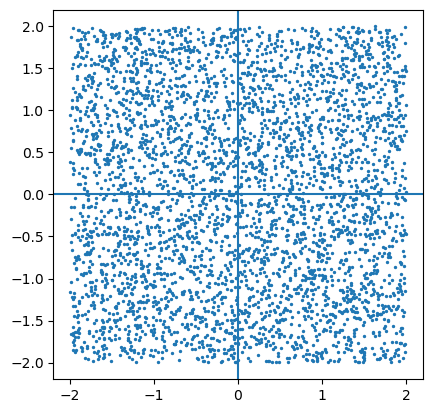

In [10]:
plt.gca().set_aspect('equal')
plt.scatter(*Zs_pre.T, s=2)
plt.axhline(y=0); plt.axvline(x=0)

In [11]:
# P = np.exp(-2-80*np.max(np.abs(Zs[:,None,:] - Zs[None,:,:])**2, axis=-1))
P = np.exp(- np.exp(10*np.max(np.abs(Zs_pre[:,None,:] - Zs_pre[None,:,:]), axis=-1)))

In [12]:
P, P.shape

(array([[3.67879441e-01, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 3.67879441e-01, 0.00000000e+00, ...,
         0.00000000e+00, 8.10480853e-68, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00, 3.67879441e-01, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        ...,
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         3.67879441e-01, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 8.10480853e-68, 0.00000000e+00, ...,
         0.00000000e+00, 3.67879441e-01, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 3.67879441e-01]]),
 (4000, 4000))

In [13]:
ths = np.random.random((n_pre, n_pre))

In [14]:
Adj_pre = (ths <= rho * P).astype(int)
Adj_pre[np.arange(n_pre), np.arange(n_pre)] = 0
Adj_pre[*np.tril_indices(n_pre)] = Adj_pre.T[*np.tril_indices(n_pre)]

Text(0, 0.5, 'freq')

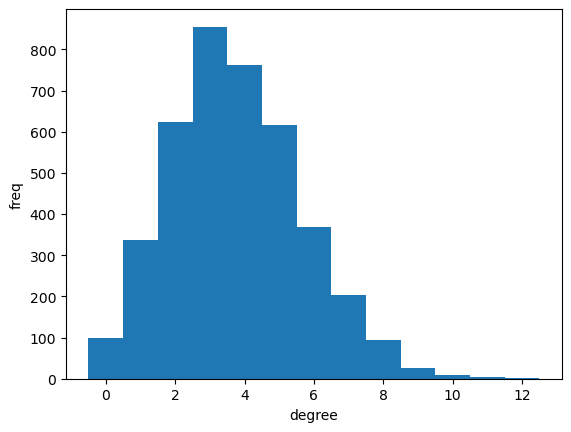

In [15]:
plt.hist(np.sum(Adj_pre,0), np.arange(np.max(np.sum(Adj_pre,0))+1)-0.5)
plt.xlabel('degree'); plt.ylabel('freq')

In [16]:
id_node = np.argsort(np.max(np.abs(Zs_pre), -1))[:n_node]

In [17]:
Adj = Adj_pre[id_node[:,None],id_node]
Zs = Zs_pre[id_node]

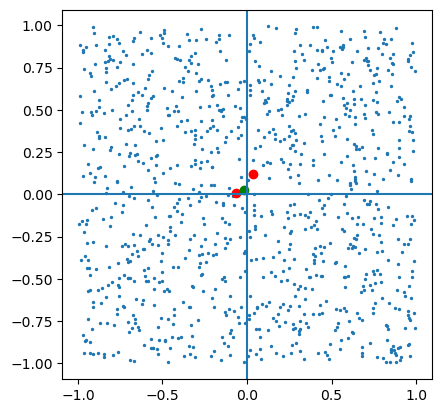

In [18]:
plt.gca().set_aspect('equal')
plt.scatter(*Zs.T, s=2)
plt.scatter(*Zs[Adj[0]==1].T, color='red')
plt.scatter(*Zs[0], color='green')
plt.axhline(y=0); plt.axvline(x=0)

In [19]:
G = KECENI.Graph(Adj, Zs)

In [20]:
row, col = np.where(Adj != 0)

Text(0, 0.5, '$Z_{i2}$')

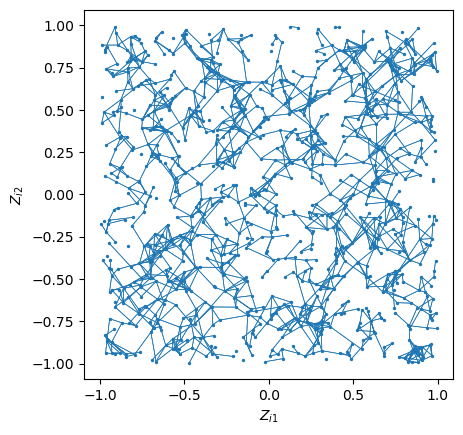

In [21]:
plt.gca().set_aspect('equal')
plt.scatter(*Zs.T, s=2)

for i, (r,c) in enumerate(zip(row, col)):
    plt.plot(*Zs[[r,c]].T, color='C0', linewidth=0.5)
    
plt.xlabel(r'$Z_{i1}$'); plt.ylabel(r'$Z_{i2}$')

In [22]:
data_latent = pd.DataFrame({'Z1': Zs[:,0], 'Z2': Zs[:,1]})
data_network = pd.DataFrame({'row': row+1, 'col': col+1})

In [23]:
data_latent.to_feather('%s/latent.feather'%save_dir)
data_network.to_feather('%s/network.feather'%save_dir)

# features

In [24]:
for i_sim in np.arange(n_sim):
    Xs = rX(1, np.arange(n_node), G)[0]

    ps = np.array([
        pij(1, Xs[G.N1(i)], G.sub(G.N1(i))) 
        for i in np.arange(n_node)
    ])

    Ts = np.random.binomial(1, ps) 

    ms = np.array([
        mu(Ts[G.N1(i)], Xs[G.N2(i)], G.sub(G.N2(i))) 
        for i in np.arange(n_node)
    ])

    Ys = np.random.normal(ms, 1)

    data_feature = pd.DataFrame({
        'X1': Xs[:,0], 'X2': Xs[:,1], 'X3': Xs[:,2],
        'p': ps, 'T': Ts, 'm': ms, 'Y': Ys
    })

    data_feature.to_feather(
        '%s/feature_%.3d.feather'%(save_dir, i_sim)
    )

# check

In [25]:
i_sim = 0

In [26]:
data_feature = pd.read_feather(
    '%s/feature_%.3d.feather'%(save_dir, i_sim)
)

(array([ 17.,  65., 106., 130., 163., 164., 149., 118.,  70.,  18.]),
 array([0.05021367, 0.14074272, 0.23127178, 0.32180084, 0.4123299 ,
        0.50285895, 0.59338801, 0.68391707, 0.77444613, 0.86497518,
        0.95550424]),
 <BarContainer object of 10 artists>)

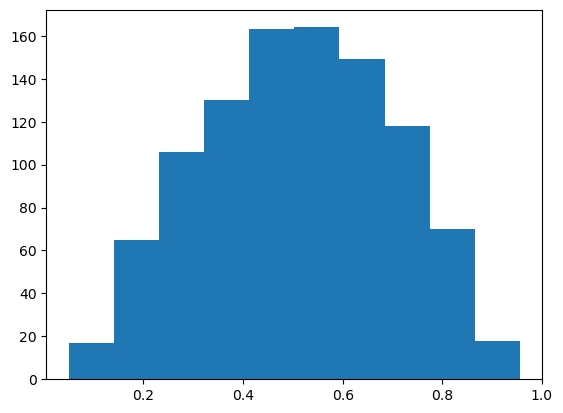

In [27]:
plt.hist(data_feature['p'])

In [28]:
np.mean(data_feature['T'])

0.507

(array([ 13.,  48., 148., 218., 257., 197.,  75.,  33.,   9.,   2.]),
 array([-8.85476535, -6.82520837, -4.79565138, -2.7660944 , -0.73653741,
         1.29301957,  3.32257656,  5.35213354,  7.38169053,  9.41124751,
        11.4408045 ]),
 <BarContainer object of 10 artists>)

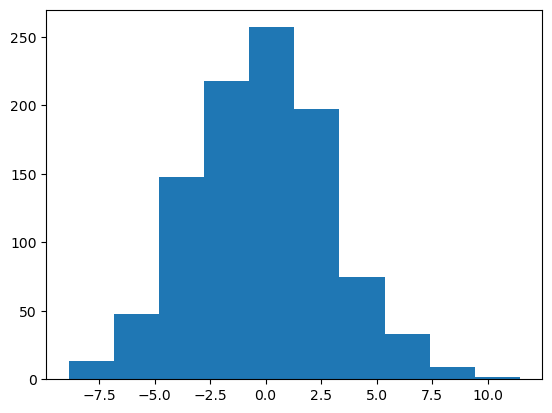

In [29]:
plt.hist(data_feature['Y'])

(array([  8.,  32.,  72., 100., 127.,  96.,  47.,  18.,   3.,   4.]),
 array([-8.17954579, -6.34482596, -4.51010612, -2.67538629, -0.84066645,
         0.99405338,  2.82877322,  4.66349305,  6.49821289,  8.33293273,
        10.16765256]),
 <BarContainer object of 10 artists>)

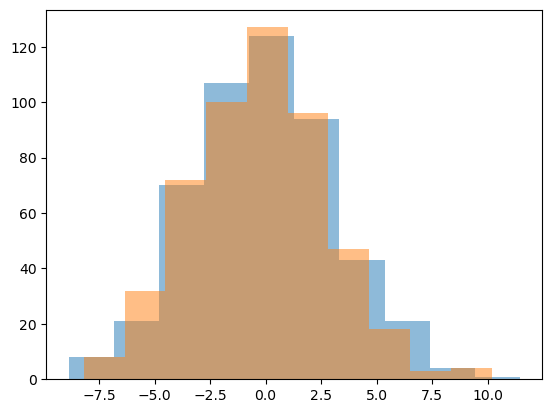

In [30]:
plt.hist(data_feature.query('T == 0')['Y'], alpha=0.5)
plt.hist(data_feature.query('T == 1')['Y'], alpha=0.5)

In [31]:
np.mean(data_feature.query('T == 0')['Y']), np.mean(data_feature.query('T == 1')['Y'])

(-0.05865278037583858, -0.2617592075187061)

(array([  2.,   2.,  14.,  50., 127., 126., 103.,  58.,  20.,   5.]),
 array([-3.54617113, -2.85534749, -2.16452384, -1.4737002 , -0.78287656,
        -0.09205291,  0.59877073,  1.28959437,  1.98041802,  2.67124166,
         3.3620653 ]),
 <BarContainer object of 10 artists>)

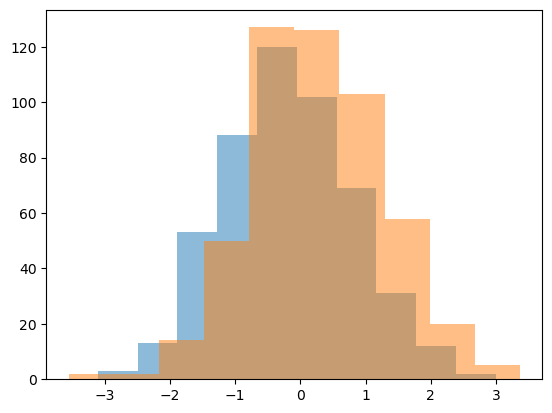

In [32]:
plt.hist(data_feature.query('T == 0')['X1'], alpha=0.5)
plt.hist(data_feature.query('T == 1')['X1'], alpha=0.5)

(array([  2.,   2.,  24.,  51.,  99., 126., 113.,  60.,  21.,   9.]),
 array([-3.17474811, -2.57153838, -1.96832866, -1.36511893, -0.7619092 ,
        -0.15869948,  0.44451025,  1.04771998,  1.65092971,  2.25413943,
         2.85734916]),
 <BarContainer object of 10 artists>)

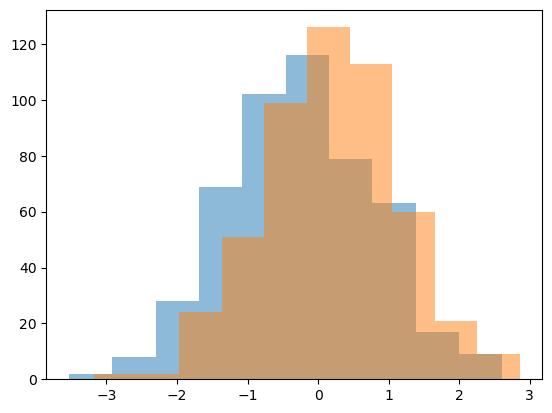

In [33]:
plt.hist(data_feature.query('T == 0')['X2'], alpha=0.5)
plt.hist(data_feature.query('T == 1')['X2'], alpha=0.5)

(array([  3.,  12.,  35.,  84., 128., 126.,  72.,  36.,   9.,   2.]),
 array([-2.94839817, -2.29841329, -1.64842841, -0.99844353, -0.34845864,
         0.30152624,  0.95151112,  1.601496  ,  2.25148089,  2.90146577,
         3.55145065]),
 <BarContainer object of 10 artists>)

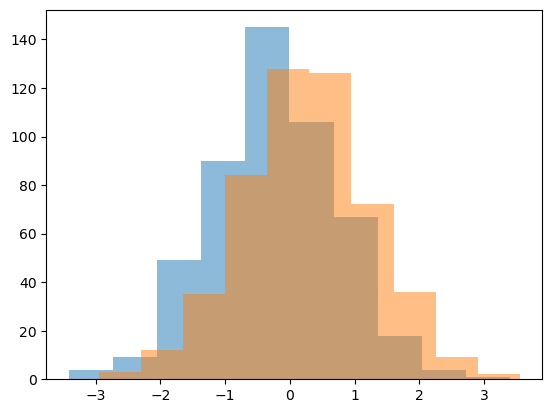

In [34]:
plt.hist(data_feature.query('T == 0')['X3'], alpha=0.5)
plt.hist(data_feature.query('T == 1')['X3'], alpha=0.5)

In [35]:
ix = np.array([0, 1, 2, 5, 6])

In [36]:
np.mean(data_feature.query('T == 0').iloc[:,ix], 0)

X1   -0.170299
X2   -0.235809
X3   -0.230722
m    -0.101816
Y    -0.058653
dtype: float64

In [37]:
np.mean(data_feature.query('T == 1').iloc[:,ix], 0)

X1    0.278029
X2    0.206821
X3    0.280092
m    -0.271009
Y    -0.261759
dtype: float64

In [38]:
np.mean(data_feature.query('T == 1').iloc[:,ix], 0) - np.mean(data_feature.query('T == 0').iloc[:,ix], 0)

X1    0.448328
X2    0.442630
X3    0.510814
m    -0.169192
Y    -0.203106
dtype: float64